### Pre-requisites before running the notebook

In [10]:
# Create directory structure
import os
for d in [
    "../processed_data/splits",
    "../processed_data/annotation_summaries",
    "../checkpoints",
    "../logs",
    "../results/predictions"
]:
    os.makedirs(d, exist_ok=True)
    print(f"✓ {d}")

✓ ../processed_data/splits
✓ ../processed_data/annotation_summaries
✓ ../checkpoints
✓ ../logs
✓ ../results/predictions


In [9]:
# Download and extract the AI2D dataset
import os
import urllib.request
import zipfile

DATA_URL = "https://ai2-public-datasets.s3.amazonaws.com/diagrams/ai2d-all.zip"
ZIP_FILE = "../ai2d-all.zip"
EXTRACT_DIR = "../ai2d"

if not os.path.exists(EXTRACT_DIR):
    print("Downloading AI2D dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_FILE)

    print("Extracting...")
    with zipfile.ZipFile(ZIP_FILE, "r") as zip_ref:
        zip_ref.extractall(".")

    os.remove(ZIP_FILE)
    print("Done!")
else:
    print("AI2D dataset already exists.")

print(f"\nDataset available at: {os.path.abspath(EXTRACT_DIR)}")

AI2D dataset already exists.

Dataset available at: /home/matty/Documents/UE_DataScience/Sem_II/Machine Learning/VLM_FInal_Project/FINAL/AI2D-VQA-MLProject/ai2d


### Run the metadata_generator.py script in the root dir

## EDA :-

### Imports

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import json
import os
from PIL import Image
import random
from collections import defaultdict

random.seed(42)

df_img = pd.read_csv("../metadata_output/metadata_images.csv")
df_q   = pd.read_csv("../metadata_output/metadata_questions.csv")
with open("../ai2d/categories.json") as f:
    categories = json.load(f)

print(f"Before filtering:-")
print(f"Images:    {len(df_img)}")
print(f"Questions: {len(df_q)}")

Before filtering:-
Images:    4903
Questions: 15501


### 01 -  Category distribution

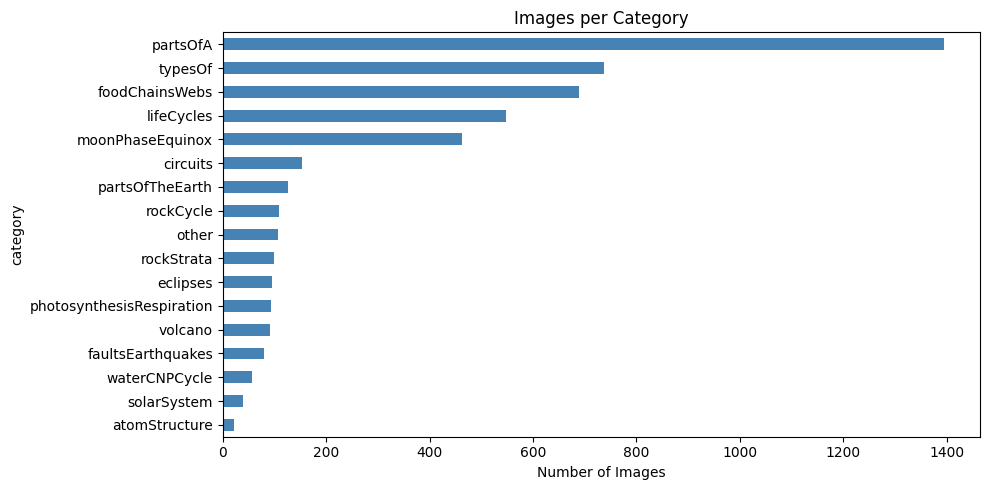

category
partsOfA                     1395
typesOf                       738
foodChainsWebs                689
lifeCycles                    547
moonPhaseEquinox              462
circuits                      153
partsOfTheEarth               127
rockCycle                     108
other                         107
rockStrata                     99
eclipses                       95
photosynthesisRespiration      93
volcano                        91
faultsEarthquakes              80
waterCNPCycle                  57
solarSystem                    40
atomStructure                  22
Name: count, dtype: int64


In [11]:
cat_counts = df_img["category"].value_counts()

plt.figure(figsize=(10, 5))
cat_counts.sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("Number of Images")
plt.title("Images per Category")
plt.tight_layout()
plt.savefig("../results/eda_category_dist.png", dpi=150)
plt.show()

print(cat_counts)

### 02 -  Questions per image distribution

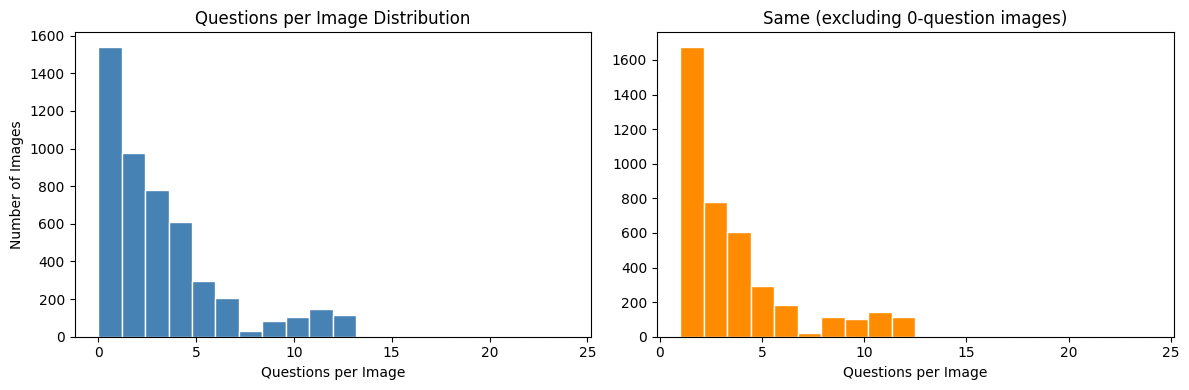

Images with 0 questions:  843
Mean questions per image: 3.82
Max questions per image:  24


In [12]:
q_counts = df_img["q_question_count"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(q_counts, bins=20, color="steelblue", edgecolor="white")
axes[0].set_xlabel("Questions per Image")
axes[0].set_ylabel("Number of Images")
axes[0].set_title("Questions per Image Distribution")

axes[1].hist(q_counts[q_counts > 0], bins=20, color="darkorange", edgecolor="white")
axes[1].set_xlabel("Questions per Image")
axes[1].set_title("Same (excluding 0-question images)")

plt.tight_layout()
plt.savefig("../results/eda_questions_per_image.png", dpi=150)
plt.show()

print(f"Images with 0 questions:  {(q_counts == 0).sum()}")
print(f"Mean questions per image: {q_counts[q_counts > 0].mean():.2f}")
print(f"Max questions per image:  {q_counts.max()}")

### 03 - abcLabel breakdown per category

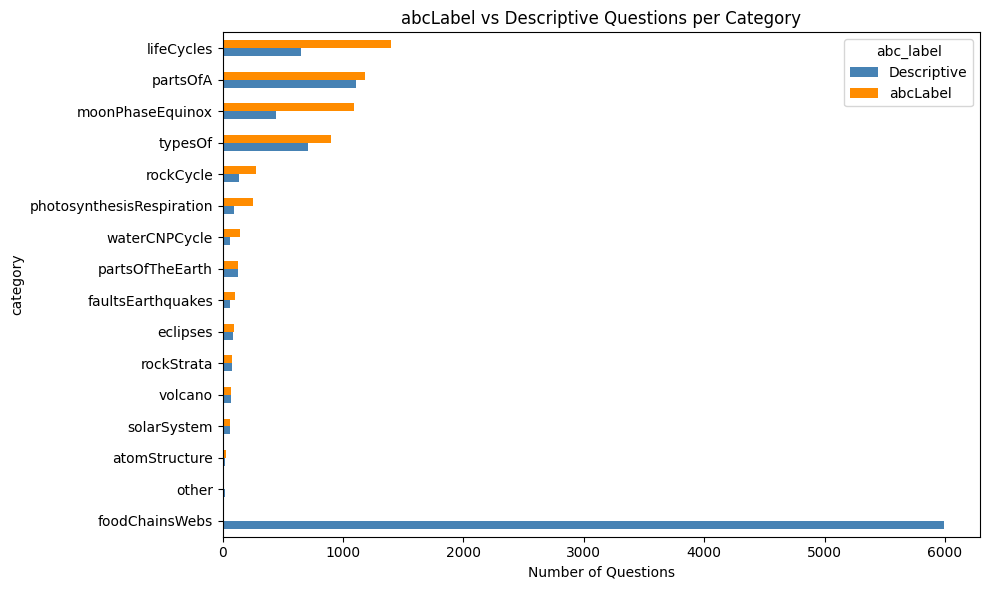

abc_label                  Descriptive  abcLabel
category                                        
atomStructure                       16        24
eclipses                            82        96
faultsEarthquakes                   61        99
foodChainsWebs                    5992         0
lifeCycles                         653      1401
moonPhaseEquinox                   441      1094
other                               22         0
partsOfA                          1110      1185
partsOfTheEarth                    128       123
photosynthesisRespiration           95       247
rockCycle                          132       276
rockStrata                          79        79
solarSystem                         60        58
typesOf                            712       896
volcano                             66        68
waterCNPCycle                       59       147


In [13]:
abc_merged = df_q.merge(df_img[["image_name", "category"]], on="image_name")

abc_by_cat = (
    abc_merged.groupby(["category", "abc_label"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={True: "abcLabel", False: "Descriptive"})
)

abc_by_cat.sort_values("abcLabel", ascending=True).plot(
    kind="barh", figsize=(10, 6), color=["steelblue", "darkorange"]
)
plt.xlabel("Number of Questions")
plt.title("abcLabel vs Descriptive Questions per Category")
plt.tight_layout()
plt.savefig("../results/eda_abclabel_by_category.png", dpi=150)
plt.show()

print(abc_by_cat)

### 04 - Correct answer index distribution (bias check)

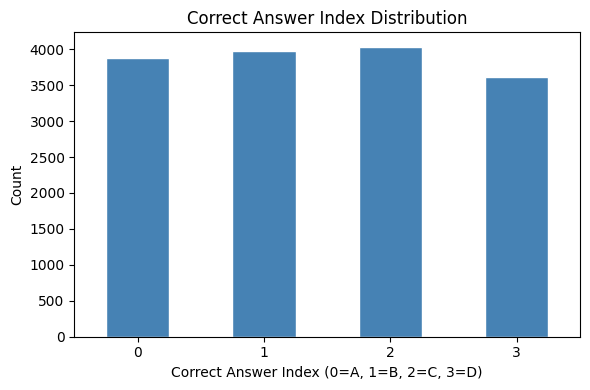

correct_answer_index
0    3881
1    3976
2    4034
3    3610
Name: count, dtype: int64

Most common index: 2 (4034 questions)
Least common index: 3 (3610 questions)


In [14]:
idx_dist = df_q["correct_answer_index"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
idx_dist.plot(kind="bar", color="steelblue", edgecolor="white", rot=0)
plt.xlabel("Correct Answer Index (0=A, 1=B, 2=C, 3=D)")
plt.ylabel("Count")
plt.title("Correct Answer Index Distribution")
plt.tight_layout()
plt.savefig("../results/eda_answer_bias.png", dpi=150)
plt.show()

print(idx_dist)
print(f"\nMost common index: {idx_dist.idxmax()} ({idx_dist.max()} questions)")
print(f"Least common index: {idx_dist.idxmin()} ({idx_dist.min()} questions)")

### 05 - Annotation richness per category

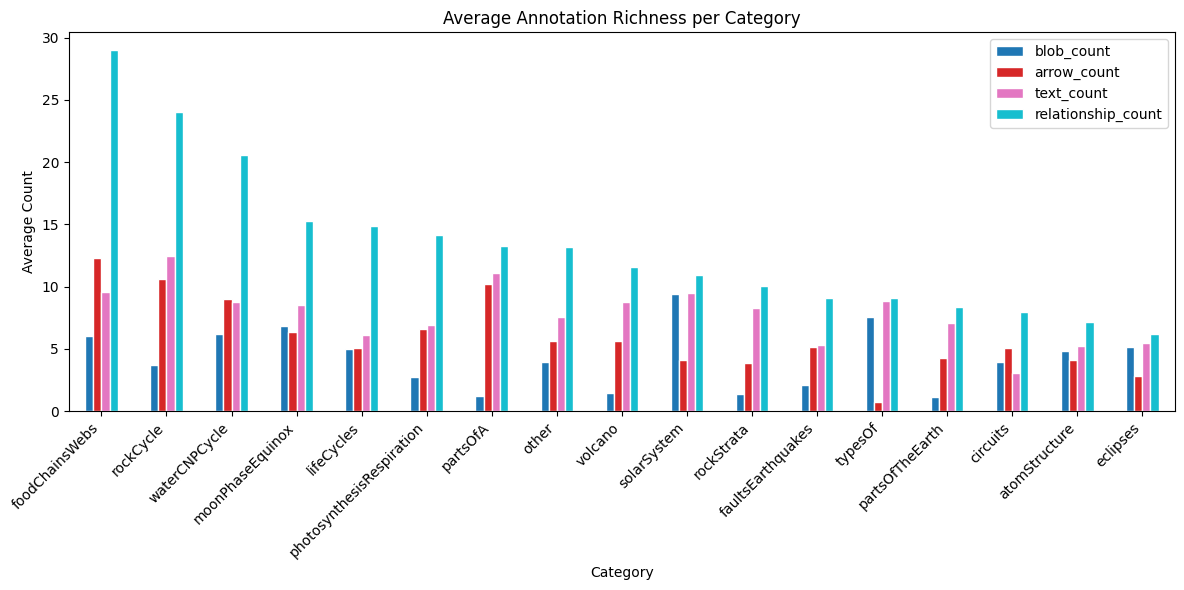

                           blob_count  arrow_count  text_count  \
category                                                         
foodChainsWebs                   6.02        12.28        9.59   
rockCycle                        3.74        10.60       12.49   
waterCNPCycle                    6.19         9.00        8.79   
moonPhaseEquinox                 6.87         6.37        8.50   
lifeCycles                       4.95         5.10        6.13   
photosynthesisRespiration        2.75         6.59        6.88   
partsOfA                         1.24        10.20       11.10   
other                            3.96         5.64        7.54   
volcano                          1.42         5.59        8.74   
solarSystem                      9.38         4.12        9.52   
rockStrata                       1.39         3.90        8.26   
faultsEarthquakes                2.11         5.12        5.32   
typesOf                          7.59         0.75        8.83   
partsOfThe

In [15]:
ann_cols = ["blob_count", "arrow_count", "text_count", "relationship_count"]

richness = df_img.groupby("category")[ann_cols].mean().round(2)
richness = richness.sort_values("relationship_count", ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
richness.plot(kind="bar", ax=ax, colormap="tab10", edgecolor="white")
ax.set_xlabel("Category")
ax.set_ylabel("Average Count")
ax.set_title("Average Annotation Richness per Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("../results/eda_annotation_richness.png", dpi=150)
plt.show()

print(richness)

### 06 - Sample image viewer

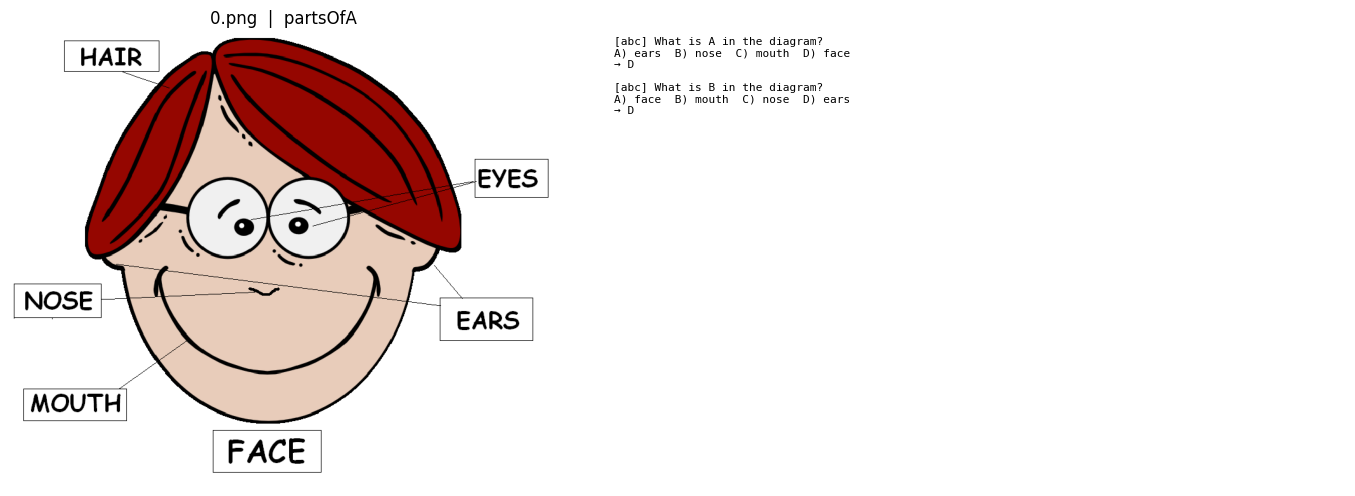

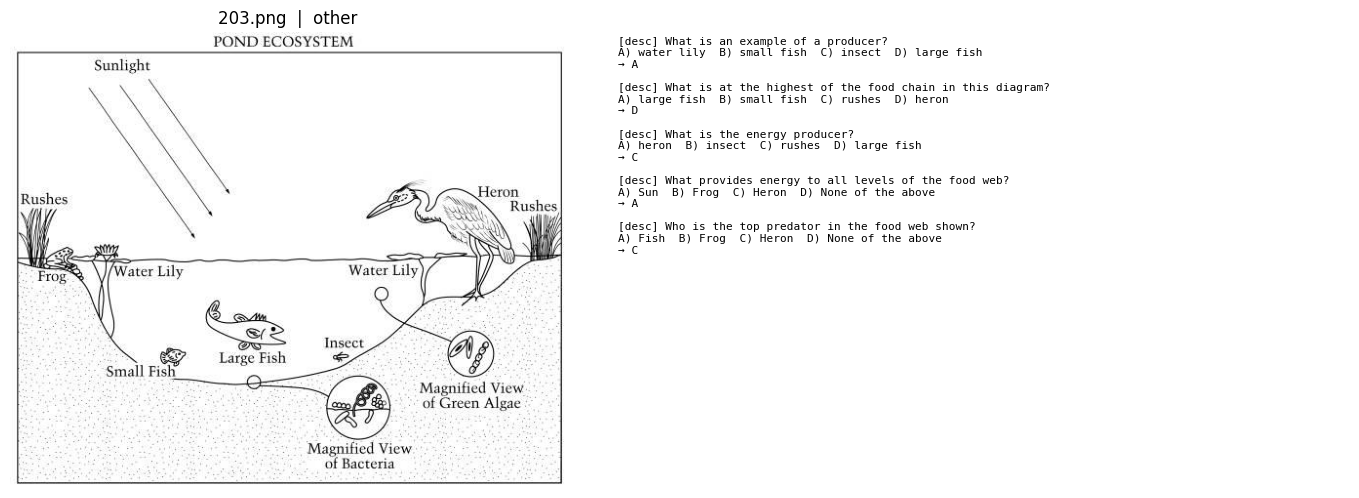

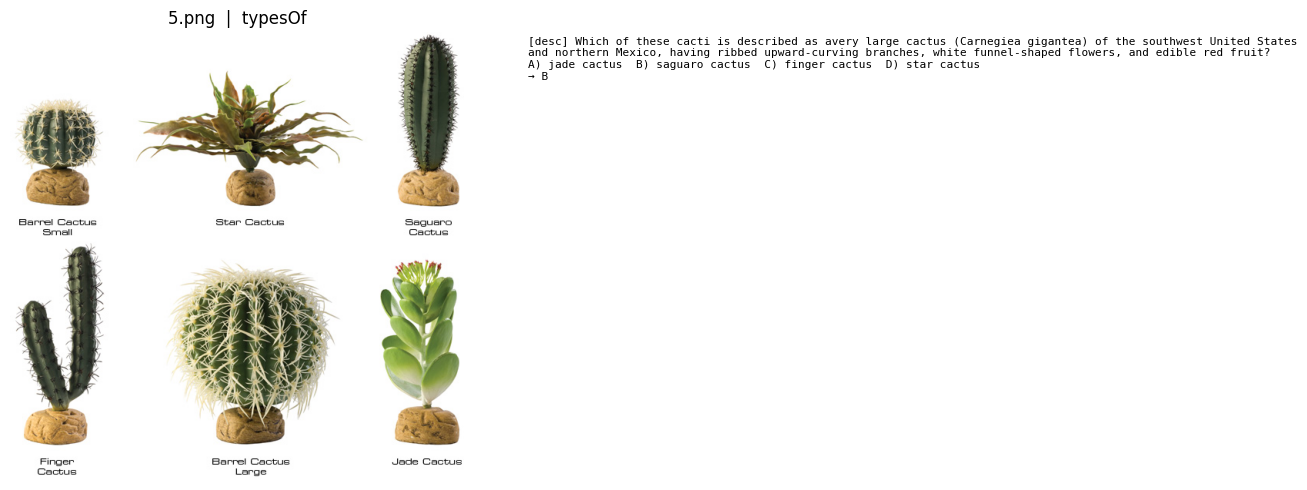

/tmp/ipykernel_85600/1325799655.py:30: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


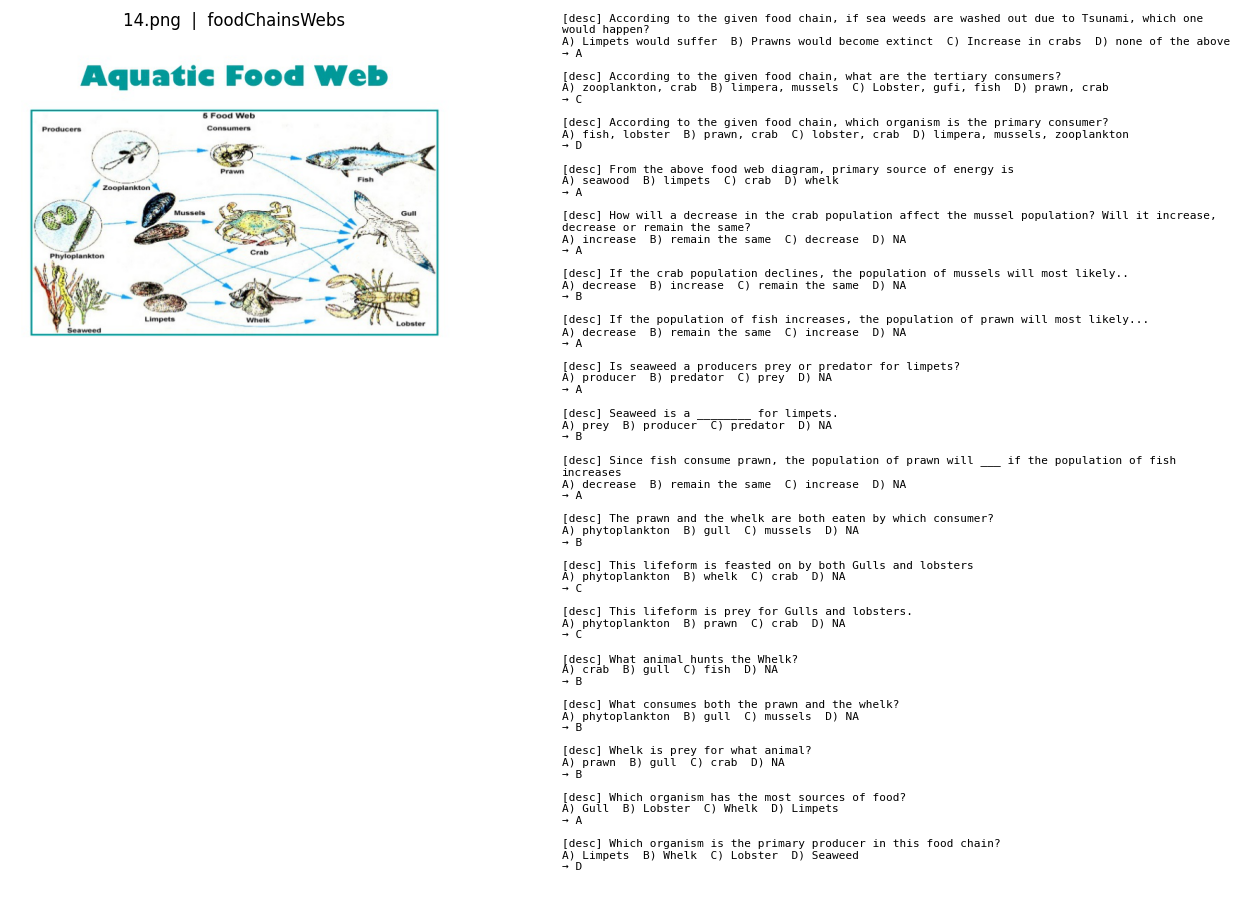

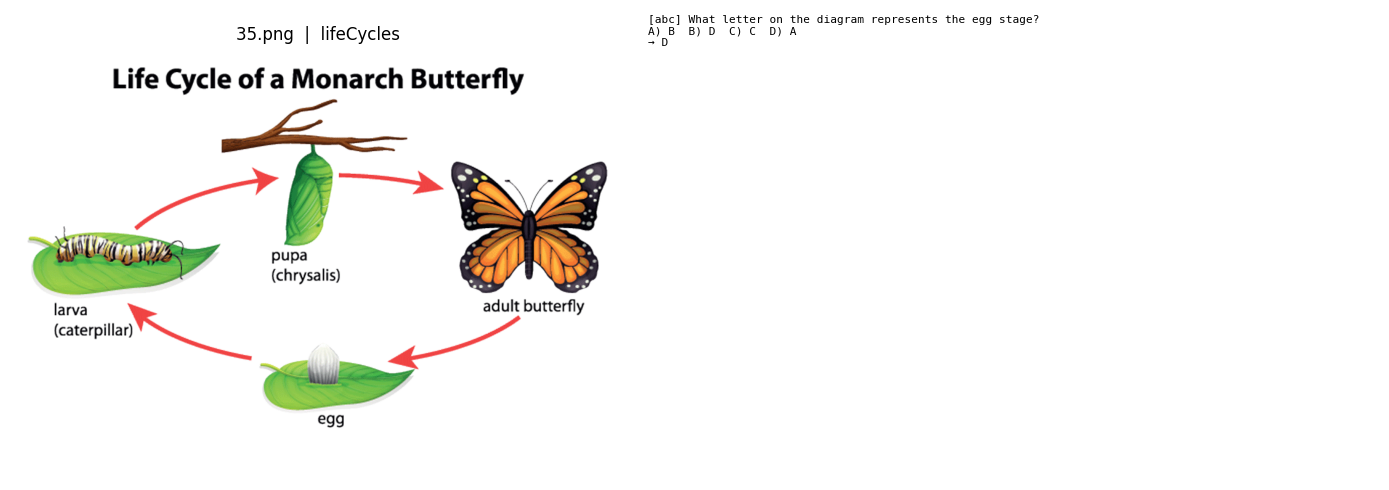

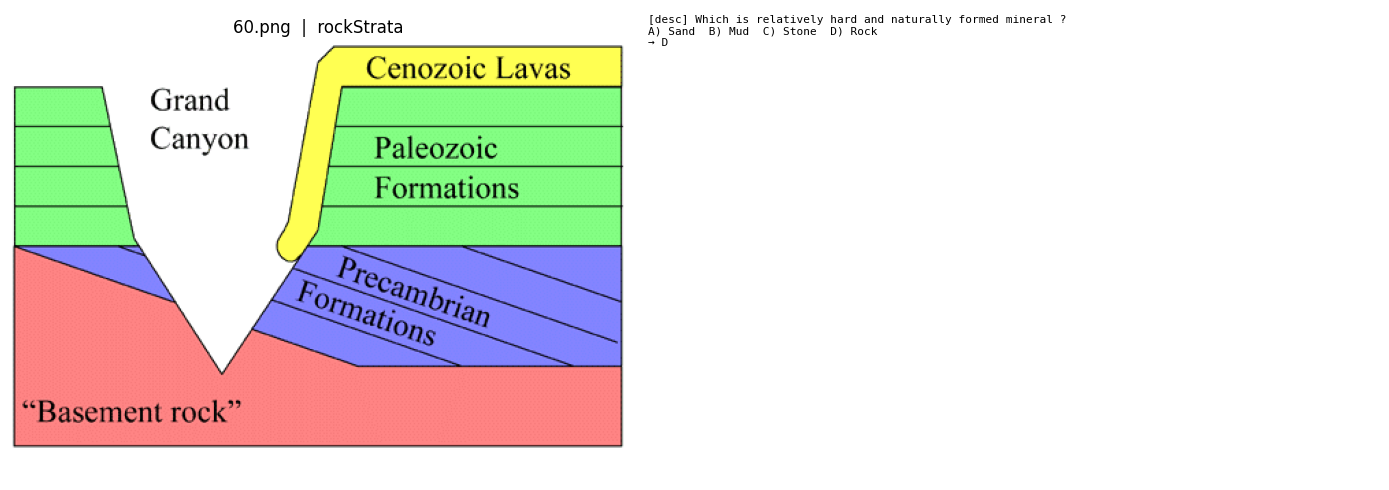

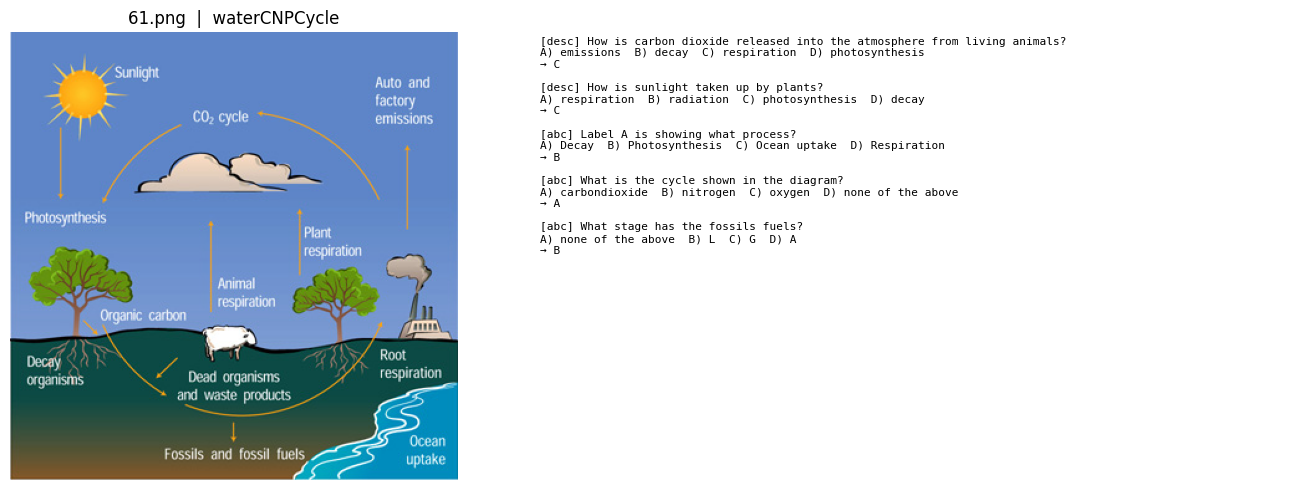

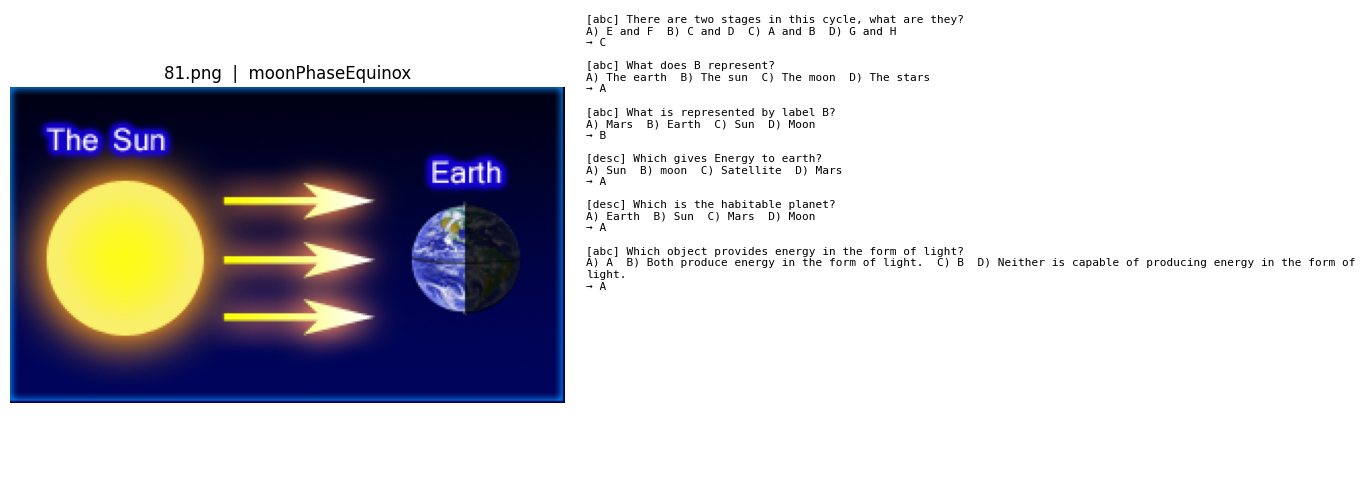

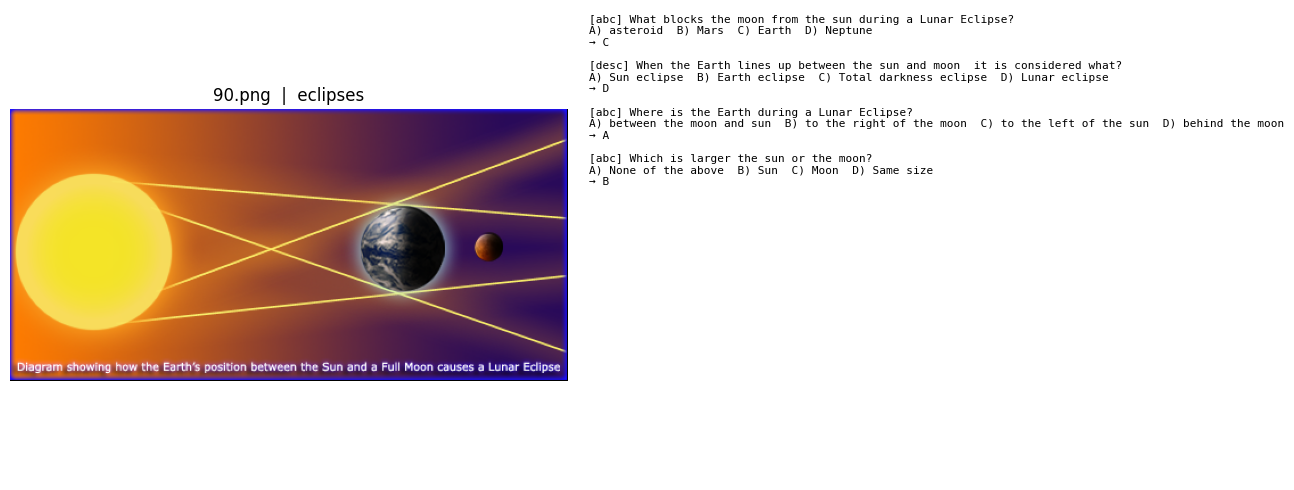

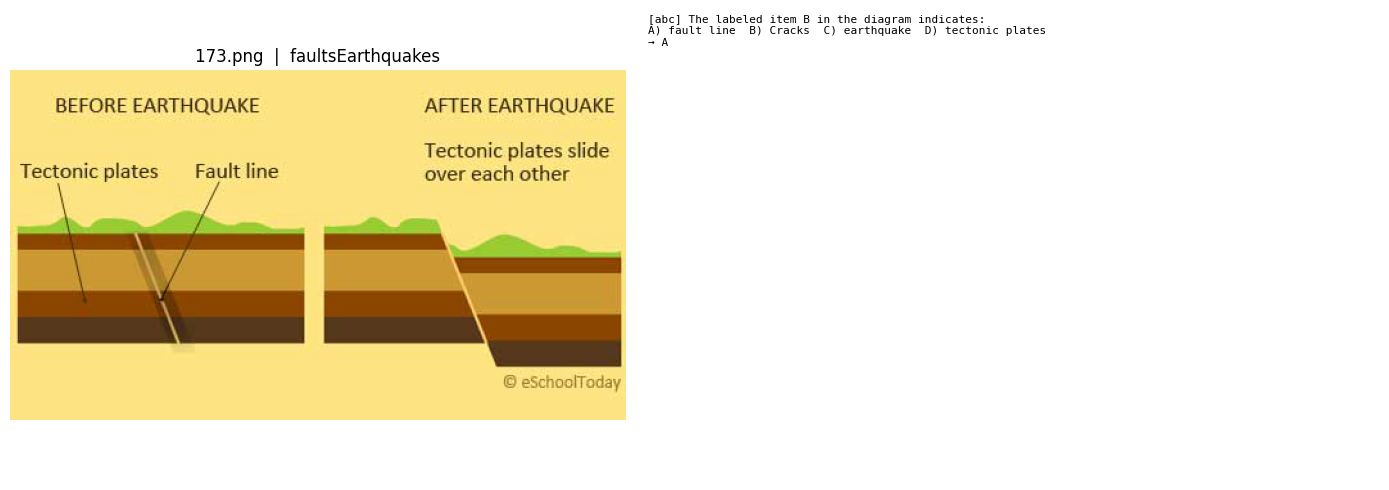

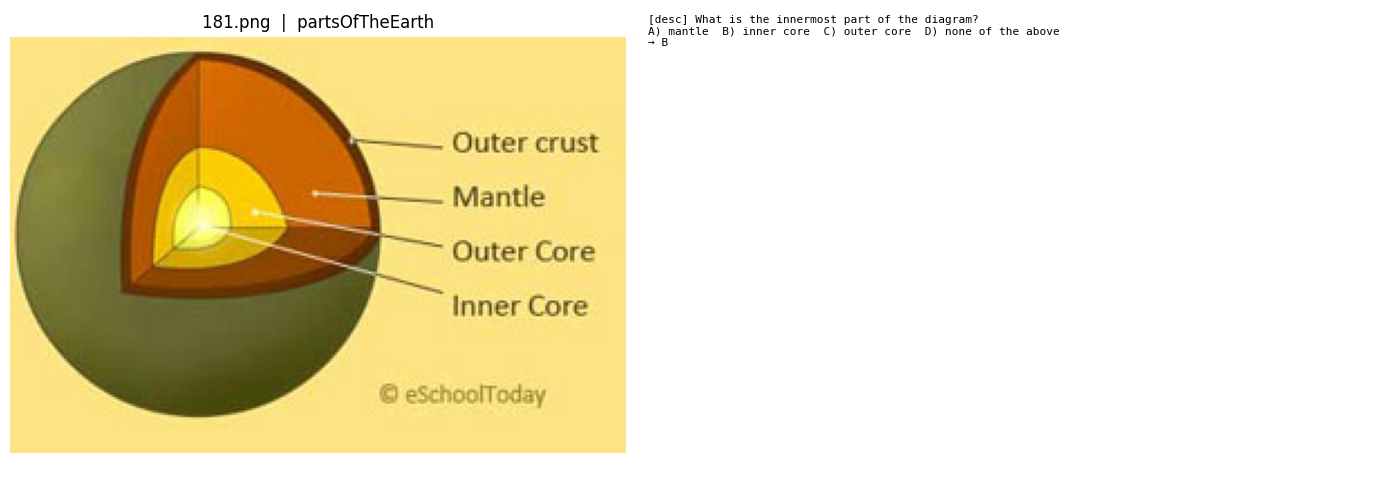

Skipping 'circuits' — no images with questions


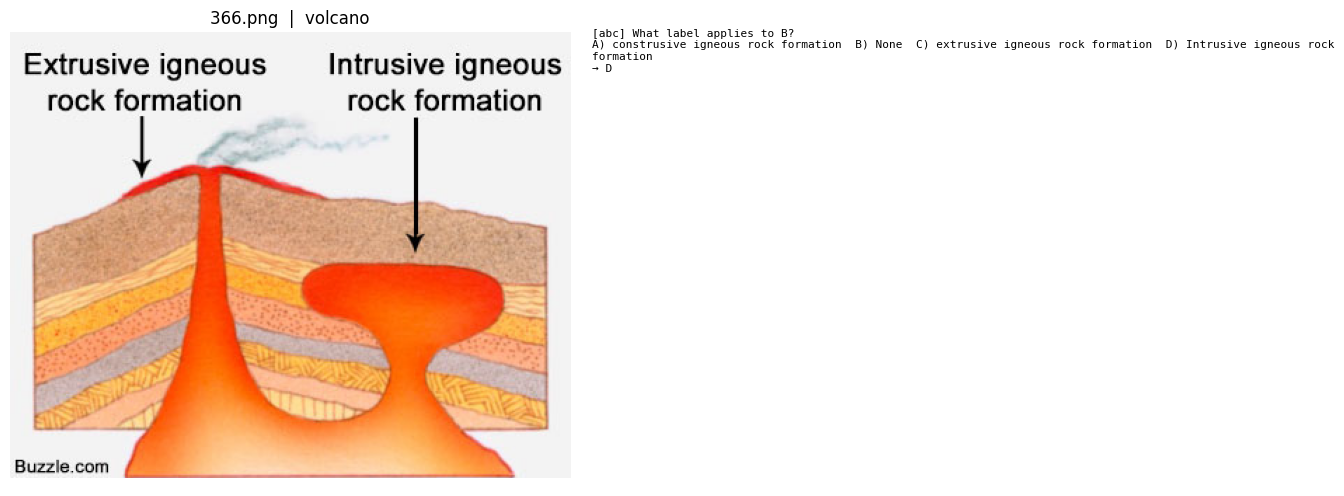

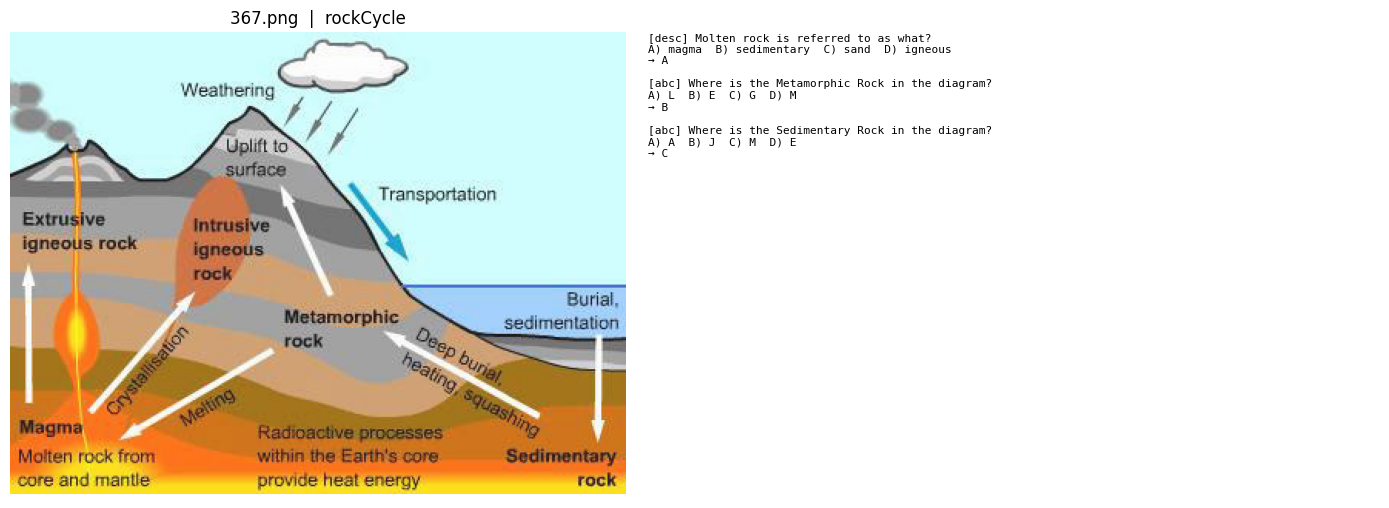

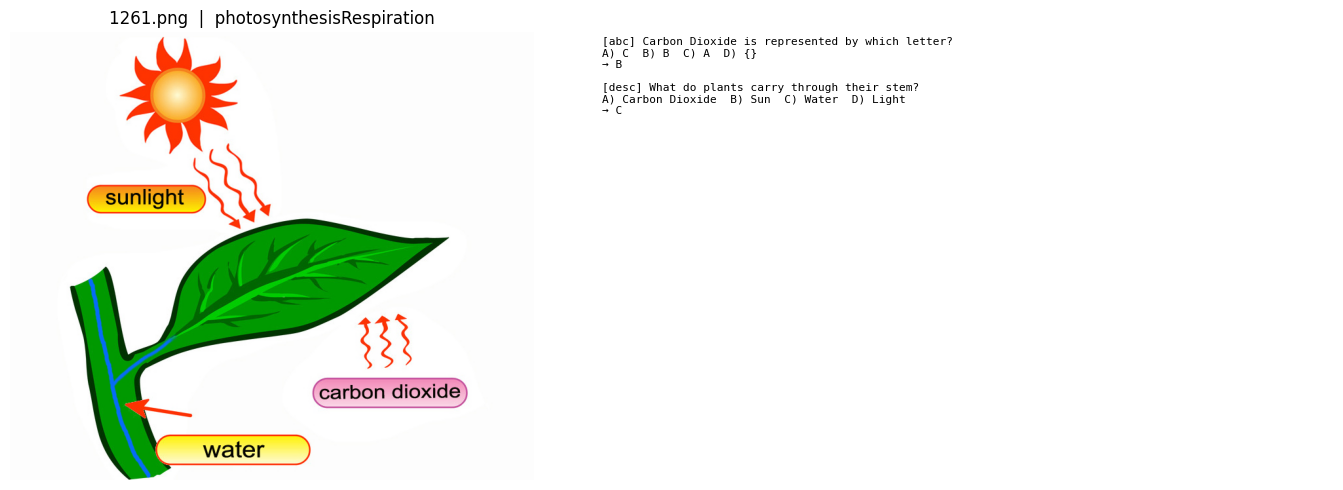

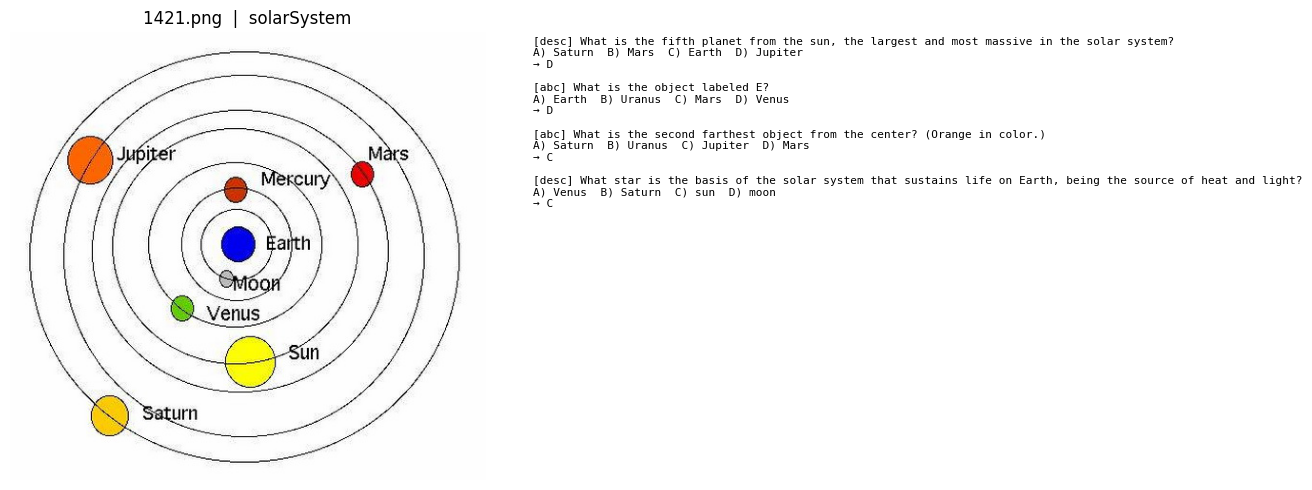

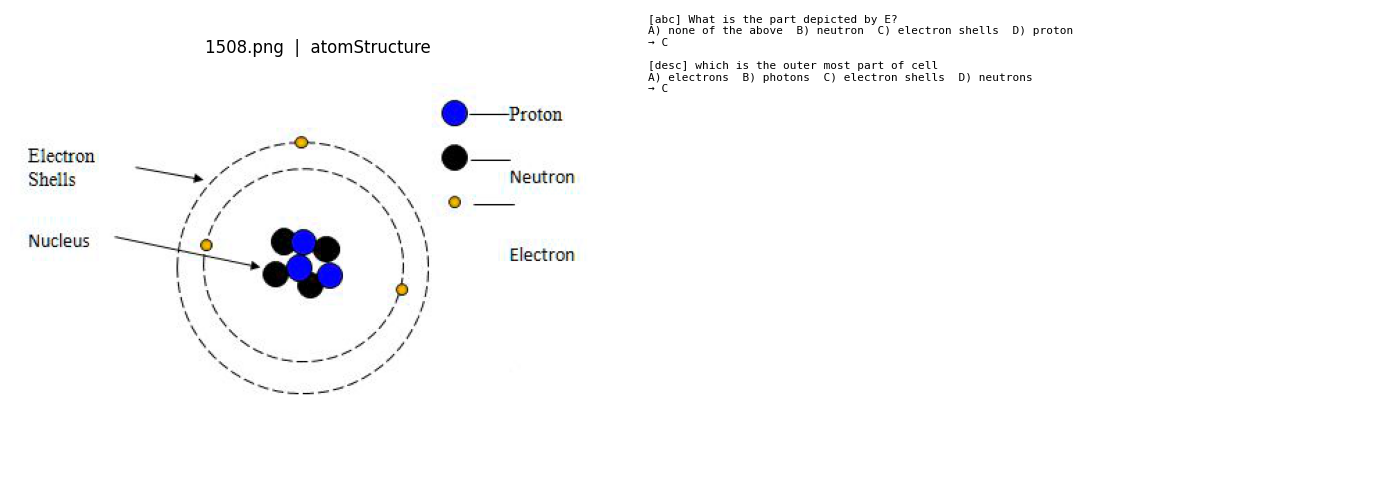

In [16]:
def show_sample(image_name):
    img_path = f"../ai2d/images/{image_name}"
    q_rows   = df_q[df_q["image_name"] == image_name]
    cat      = df_img[df_img["image_name"] == image_name]["category"].values[0]

    fig = plt.figure(figsize=(14, 5))
    gs  = gridspec.GridSpec(1, 2, width_ratios=[1, 1.2])

    # Image
    ax0 = fig.add_subplot(gs[0])
    ax0.imshow(Image.open(img_path))
    ax0.set_title(f"{image_name}  |  {cat}")
    ax0.axis("off")

    # Questions
    ax1 = fig.add_subplot(gs[1])
    ax1.axis("off")
    text = ""
    for _, row in q_rows.iterrows():
        answers = row["answer_texts"].split(" | ")
        options = ["A","B","C","D"]
        choices = "  ".join(f"{options[i]}) {a}" for i, a in enumerate(answers))
        correct = options[int(row["correct_answer_index"])]
        abc_tag = "[abc]" if row["abc_label"] else "[desc]"
        text += f"{abc_tag} {row['question_text']}\n{choices}\n→ {correct}\n\n"

    ax1.text(0.01, 0.99, text, va="top", ha="left",
             fontsize=8, family="monospace", transform=ax1.transAxes,
             wrap=True)
    plt.tight_layout()
    plt.show()

# Show one sample per category
for cat in df_img["category"].unique():
    subset = df_img[
        (df_img["category"] == cat) & (df_img["q_question_count"] > 0)
    ]
    if subset.empty:
        print(f"Skipping '{cat}' — no images with questions")
        continue
    show_sample(subset["image_name"].iloc[0])

## Data Preprocessing :-

### Drop Un-usable Imgs

In [17]:
# Drop 1: images with no question file
# Drop 2: images with a question file but 0 actual questions inside
df_img = df_img[df_img["q_question_count"] > 0].reset_index(drop=True)

# Keep only questions belonging to remaining images
valid_images = set(df_img["image_name"])
df_q = df_q[df_q["image_name"].isin(valid_images)].reset_index(drop=True)

print(f"After filtering: {len(df_img)} images, {len(df_q)} questions")

After filtering: 4060 images, 15501 questions


### 01 - Stratified dataset split

In [18]:
by_category = defaultdict(list)
for img in df_img["image_name"]:
    cat = categories.get(img, "other")
    by_category[cat].append(img)

train_imgs, val_imgs, test_imgs = [], [], []

for cat, imgs in by_category.items():
    random.shuffle(imgs)
    n      = len(imgs)
    n_test = max(1, int(n * 0.15))
    n_val  = max(1, int(n * 0.15))
    test_imgs  += imgs[:n_test]
    val_imgs   += imgs[n_test:n_test + n_val]
    train_imgs += imgs[n_test + n_val:]

print(f"Train: {len(train_imgs)} | Val: {len(val_imgs)} | Test: {len(test_imgs)}")

# Sanity check — no overlap
assert not set(train_imgs) & set(val_imgs), "Train/Val overlap!"
assert not set(train_imgs) & set(test_imgs), "Train/Test overlap!"
assert not set(val_imgs)   & set(test_imgs), "Val/Test overlap!"
print("✓ No overlap between splits")

Train: 2858 | Val: 601 | Test: 601
✓ No overlap between splits


In [19]:
# Verify category distribution across splits
split_map = (
    {img: "train" for img in train_imgs} |
    {img: "val"   for img in val_imgs}   |
    {img: "test"  for img in test_imgs}
)

df_img["split"] = df_img["image_name"].map(split_map)
df_img["category"] = df_img["image_name"].map(categories)

check = df_img.groupby(["category", "split"]).size().unstack(fill_value=0)
check["total"] = check.sum(axis=1)
check["train%"] = (check["train"] / check["total"] * 100).round(1)
check["val%"]   = (check["val"]   / check["total"] * 100).round(1)
check["test%"]  = (check["test"]  / check["total"] * 100).round(1)

print(check[["train", "val", "test", "train%", "val%", "test%"]])

split                      train  val  test  train%  val%  test%
category                                                        
atomStructure                 14    2     2    77.8  11.1   11.1
eclipses                      59   12    12    71.1  14.5   14.5
faultsEarthquakes             52   10    10    72.2  13.9   13.9
foodChainsWebs               431   92    92    70.1  15.0   15.0
lifeCycles                   379   80    80    70.3  14.8   14.8
moonPhaseEquinox             311   66    66    70.2  14.9   14.9
other                          2    1     1    50.0  25.0   25.0
partsOfA                     765  163   163    70.1  14.9   14.9
partsOfTheEarth               81   16    16    71.7  14.2   14.2
photosynthesisRespiration     65   13    13    71.4  14.3   14.3
rockCycle                     75   16    16    70.1  15.0   15.0
rockStrata                    57   11    11    72.2  13.9   13.9
solarSystem                   29    5     5    74.4  12.8   12.8
typesOf                  

### 02 - Annotation summary builder

In [20]:
def build_annotation_context(image_name):
    ann_path = f"../ai2d/annotations/{image_name}.json"
    if not os.path.exists(ann_path):
        return ""
    with open(ann_path) as f:
        ann = json.load(f)

    texts         = ann.get("text", {})
    relationships = ann.get("relationships", {})

    # Build label lookup: tid → "Label(X)"
    label_map = {}
    for tid, t in texts.items():
        val  = t.get("value", "").strip()
        repl = t.get("replacementText", "").strip()
        if val:
            label_map[tid] = f"{val}({repl})" if repl else val

    # Build connections
    connections = []
    title       = None

    for rel in relationships.values():
        cat    = rel.get("category", "")
        origin = rel.get("origin", "")
        dest   = rel.get("destination", "")

        origin_str = label_map.get(origin)
        dest_str   = label_map.get(dest)

        if cat == "imageTitle" and origin_str:
            title = origin_str

        elif cat == "intraObjectLabel":
            # both ends are readable text nodes
            if origin_str and dest_str:
                connections.append(f"{origin_str} labels {dest_str}")
            elif origin_str:
                connections.append(f"{origin_str} → visual region")

        elif cat == "intraObjectLinkage":
            if origin_str:
                connections.append(f"{origin_str} → visual region")

    # Build context string
    context = ""
    if title:
        context += f"Diagram title: {title}\n"
    if label_map:
        context += f"Diagram labels: {', '.join(label_map.values())}\n"
    if connections:
        context += "Connections:\n" + "\n".join(f"  {c}" for c in connections) + "\n"

    return context

### 03 - Sample builder

In [21]:
def build_samples(image_names, version="A"):
    samples  = []
    options  = ["A", "B", "C", "D"]

    for img_name in image_names:
        q_rows = df_q[df_q["image_name"] == img_name]

        ann_context = ""
        if version == "B":
            ann_context = build_annotation_context(img_name)

        for _, row in q_rows.iterrows():
            answers     = row["answer_texts"].split(" | ")
            correct_idx = int(row["correct_answer_index"])

            choices_str = "  ".join(
                f"{options[i]}) {ans}" for i, ans in enumerate(answers)
            )
            correct_letter = options[correct_idx]
            correct_text   = answers[correct_idx]

            question_str = row["question_text"]
            if row["abc_label"]:
                question_str = "[Label Question] " + question_str

            user_text = f"{ann_context}Question: {question_str}\n{choices_str}"

            samples.append({
                "image_name":    img_name,
                "image_path":    f"../ai2d/images/{img_name}",
                "category":      categories.get(img_name, "other"),
                "question_id":   row["question_id"],
                "abc_label":     bool(row["abc_label"]),
                "user_text":     user_text,
                "answer":        f"{correct_letter}) {correct_text}",
                "correct_index": correct_idx,
                "version":       version,
            })

    return samples

### 04 - Build and save all splits

In [22]:
for split_name, split_imgs in [("train", train_imgs), ("val", val_imgs), ("test", test_imgs)]:
    for ver in ["A", "B"]:
        samples  = build_samples(split_imgs, version=ver)
        out_path = f"../processed_data/splits/{split_name}_v{ver}.json"
        with open(out_path, "w") as f:
            json.dump(samples, f, indent=2)
        print(f"✓ {out_path}  ({len(samples)} samples)")

✓ ../processed_data/splits/train_vA.json  (10918 samples)
✓ ../processed_data/splits/train_vB.json  (10918 samples)
✓ ../processed_data/splits/val_vA.json  (2300 samples)
✓ ../processed_data/splits/val_vB.json  (2300 samples)
✓ ../processed_data/splits/test_vA.json  (2283 samples)
✓ ../processed_data/splits/test_vB.json  (2283 samples)


### 05 -  Verify a sample from each version

In [23]:
with open("../processed_data/splits/train_vA.json") as f:
    sample_A = json.load(f)[0]

with open("../processed_data/splits/train_vB.json") as f:
    sample_B = json.load(f)[0]

print("=== Version A (image + question only) ===")
print(f"Image:    {sample_A['image_name']}")
print(f"Prompt:   {sample_A['user_text']}")
print(f"Answer:   {sample_A['answer']}")

print("\n=== Version B (image + question + annotation) ===")
print(f"Image:    {sample_B['image_name']}")
print(f"Prompt:   {sample_B['user_text']}")
print(f"Answer:   {sample_B['answer']}")

=== Version A (image + question only) ===
Image:    3020.png
Prompt:   Question: [Label Question] What is C in the diagram?
A) fall  B) style branch  C) stem  D) standard
Answer:   C) stem

=== Version B (image + question + annotation) ===
Image:    3020.png
Prompt:   Diagram labels: Standard(A), Style Branch(D), Stem(C), Fall(B)
Connections:
  Standard(A) → visual region
  Style Branch(D) → visual region
  Stem(C) → visual region
  Fall(B) → visual region
Question: [Label Question] What is C in the diagram?
A) fall  B) style branch  C) stem  D) standard
Answer:   C) stem
